<a href="https://colab.research.google.com/github/ScarrryMary/IT_MIPT_26-27_SEPMP/blob/main/Kollokvium1_group_Builova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

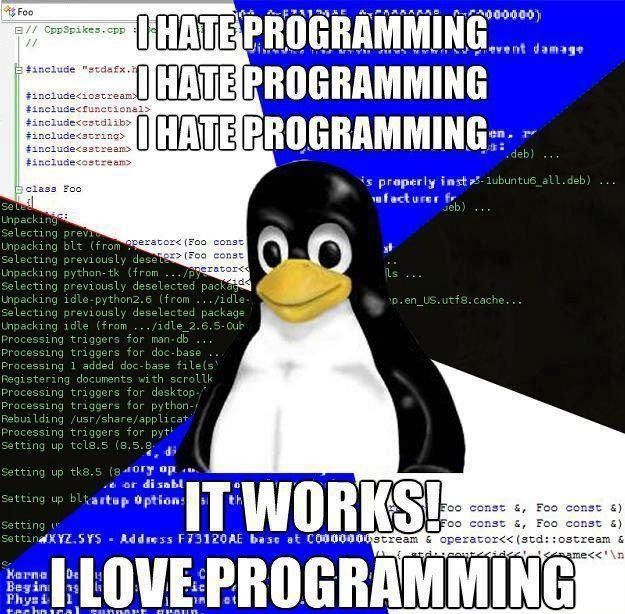

# 1. Рекурсия. Глубина рекурсии, прямой и обратный ход рекурсии. Примеры рекурсивных алгоритмов

## Стек

Прежде чем говорить о рекурсии ознакомимся со стеком вызовов! (чуть-чуть, подробнее можете прочитать в 5-м вопросе, см. ниже)

```python
def f(x, y):
  return x + 3*y
```
1) Создаётся объект типа <function..>
2) Ссылка на объект из пункта 1

- Стек - структура данных, доступ к элементам которой осуществляется по интерфейсу LIFO (Last-in First-out == "Кто последним вошел, тот первым вышел")

- Стек вызовов - стек, состоящий из стековых кадров


## Рекурсия

Рассмотрим пример:

In [2]:
def f(x):
  if x == 1: #Базовый случай/предельный случай
    return 1
  return x + f(x-1)

#f(6) = 6 + f(5) => 6 + 15 => 21
#f(5) = 5 + f(4) => 5 + 10 => 15
#f(4) = 4 + f(3) => 4 + 6 => 10
#f(3) = 3 + f(2) => 3 + 3 => 6
#f(2) = 2 + f(1) => 2 + 1 => 3

x = int(input())
print(f(x))

6
21


In [4]:
def f(x):
  if x == 0:
    return 1
  return x*f(x-1)

# f(4) = 4*f(3) <=> 4*6 = 24
# f(3) = 3*f(2) <=> 3*2 = 6
# f(2) = 2*f(1) <=> 2*1 = 2
# f(1) = 1*f(0) <=> 1*1 = 1
x = int(input())
print(f(x))

4
24


- **Глубина рекурсии** - максимально возможное количество вызовов в стеке
ИЛИ: текущий уровень в стеке.
- **Прямой ход рекурсии** - всё то, что выполняется до перехода функции в рекурсию.
- **Обратный ход рекурсии** - всё то, что выполняется после возвращения функции из рекурсии

Посмотрим, как это выглядит с подсчетом факториала:
### Пример №1: подсчет факториала

In [5]:
def f(x):
  if x == 0:
    return 1
  print('Прямой ход: x = ', x)
  res = x * f(x-1)
  print('Обратный ход: x = ', x)
  return res

print(f(5))

Прямой ход: x =  5
Прямой ход: x =  4
Прямой ход: x =  3
Прямой ход: x =  2
Прямой ход: x =  1
Обратный ход: x =  1
Обратный ход: x =  2
Обратный ход: x =  3
Обратный ход: x =  4
Обратный ход: x =  5
120


### Пример №2: Числа Фибоначчи

In [9]:
def fibonacci(n):
    if n == 0:  # Базовый случай
        return 0
    elif n == 1:  # Базовый случай
        return 1
    else:  # Рекурсивный случай
        return fibonacci(n - 1) + fibonacci(n - 2)

print(fibonacci(7))
# fib(7) => fib(6) + fib(5) == 8 + 5 = 13
# fib(6) => fib(5) + fib(4) == 5 + 3 = 8
# fib(5) => fib(4) + fib(3) == 3 + 2 = 5
# fib(4) => fib(3) + fib(2) == 2 + 1 = 3
# fib(3) => fib(2) + fib(1) == 1 + 1 = 2
# fib(2) => fib(1) + fib(0) == 1

13


### Пример №3: Алгоритм быстрого возведения в степень

In [7]:
def bin_pow(a, n):
  if n == 0:
    return 1
  if n % 2: # выполняется, если n % 2 != 0
    #print(n)
    return bin_pow(a, n-1) * a
  else: # если n % 2 == 0
    return bin_pow(a, n // 2) ** 2

print(bin_pow(2, 10))

1024


# 2. Бинарный поиск. Обоснование асимптотики

Основная последовательность действий алгоритма выглядит так:

* Сортируем массив данных.
* Делим его пополам и находим середину.
* Сравниваем срединный элемент с заданным искомым элементом.  
Если искомое число больше среднего — продолжаем поиск в правой части массива (если он отсортирован по возрастанию): делим ее пополам, повторяя пункт 3. Если же заданное число меньше — алгоритм продолжит поиск в левой части массива, снова возвращаясь к пункту 3.

Временная сложность в худшем случае — $O(logn)$, где
$𝑛$ — длина списка.

In [8]:
def bin_search(a, x):
    """Возвращает индекс x или -1, если элемент отсутствует.
    Массив a отсортирован по возрастанию.
    """
    left = 0
    right = len(a) - 1

    while left <= right:
        mid = (left + right) // 2
        value = a[mid]

        if value == x:
            return mid
        elif value < x:
            left = mid + 1
        else:
            right = mid - 1

    return -1


a = [2, 5, 8, 12, 16, 23, 38, 56, 72]

print(bin_search(a, 23))  # 5
print(bin_search(a, 10))  # -1
print(bin_search([], 10)) # -1

5
-1
-1


### Обоснование асимптотики
* Сколько раз выполняется цикл:

Пусть в текущем диапазоне находится $m$ элементов.

После проверки среднего элемента в большей из оставшихся половин будет не больше $\frac{m}{2}$
элементов.

Следовательно, размеры области поиска ограничены последовательностью: $n$, $\frac{n}{2}$, $\frac{n}{4}$, $\frac{n}{8},…$  

После $k$ итераций остаётся не более $\frac{𝑛}{2^k}$ элементов. Именно уменьшение диапазона вдвое даёт логарифмическую сложность.

Для завершения поиска достаточно, чтобы область стала пустой. С учётом целочисленного размера это гарантировано, когда
$\frac{𝑛}{2^k} < 1$.

Отсюда: $2^𝑘 > 𝑛$,   $𝑘 > log_{2}𝑛$.  

Для приведённой реализации точный максимум числа итераций при $n≥1$:

$𝑘_{max} = log_{2}𝑛 + 1$

Для пустого списка выполняется ноль итераций.

Важно: это число итераций, а не точное число всех операций сравнения в Python. Внутри одной итерации может выполняться несколько сравнений, но их количество ограничено константой.

* Сколько стоит одна итерация:  
В теле цикла выполняется фиксированное количество действий:

```python
mid = (left + right) // 2
value = a[mid]
```
Затем — сравнения и изменение одной границы.

В обычной модели анализа алгоритмов, где обращение к элементу списка по индексу и сравнение значений считаются операциями $O(1)$, стоимость одной итерации постоянна. Условие быстрого доступа по индексу существенно для логарифмической оценки.

Поэтому:

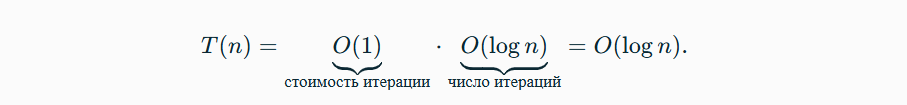

# 3. Рекурсия с мемоизацией. Проблема подсчета чисел Фибоначчи и ее решение с помощью мемоизации

***Мемоизация*** — это сохранение результатов вызовов функции, чтобы при повторном обращении с теми же аргументами не выполнять вычисления заново. Для рекурсивного вычисления чисел Фибоначчи она уменьшает время работы с экспоненциального до линейного — в модели, где сложение чисел считается операцией $O(1)$

**Числа Фибоначчи и рекурсивное определение**:   
Последовательность задаётся так:  
$F_0 = 0, F_1 = 1$,  
$F_n = F_{n−1} + F_{n−2},n≥2$

Первые значения:

```python
Индекс n:  0  1  2  3  4  5  6   7   8   9  10
F(n):     0  1  1  2  3  5  8  13  21  34  55
```
Это определение непосредственно переводится в рекурсивную функцию: для вычисления $F(n)$ функция вызывает себя для $n - 1$ и $n - 2$. При $n = 0$ или $n = 1$ дальнейшие вызовы не нужны — это базовые случаи.

Эту задачу можно решить рекурсивно:

In [9]:
def fibonacchi(n):
    if n == 0:
        return 0
    if n == 1:
        return 1
    return fibonacchi(n - 2) + fibonacchi(n - 1)

print(fibonacchi(20))

6765


Однако это будет работать очень долго. 20-е число посчитать еще можно будет, а 40-е число - нет. И не потому, что числа большие. А потому, что мы будем делать слишком много лишней работы

Почему? Потому что, чтобы посчитать N-е число, нам нужно будет независимо посчитать (N-1)-е число и (N-2)-е число, и это в минимум в два раза больше действий, чем нужно для (N-2). А значит, для подсчета N-го числа Фибоначчи необходимо 2 раза посчитать (N-2)-е число, и это занимает в два раза больше времени.
Главное, что это легко исправляется. Давайте просто не считать лишних действий - если мы один раз посчитали, то давайте запомним, чему оно равно, и в следующий раз, когда оно нам понадобится, мы используем его сразу. Удобнее всего сохранить числа Фибоначчи прямо в массиве:

In [10]:
N = 40

fib = [None] * (N + 1) # создали массив из None от 0 до N включительно
fib[0] = 0
fib[1] = 1 # заполнили изначальные позиции
for i in range(2, N + 1): # обходим массив по порядку слева направо
    fib[i] = fib[i - 2] + fib[i - 1] # формула считает новое число через предыдущие!

print(fib[40]) # ответ лежит на N-ом месте

102334155


Можно ещё вот так!

In [11]:
def fib(n, cache):
    print(f'called fib({n})')
    if cache[n] is not None:
        return cache[n]
    if n == 0:
        cache[n] = 0
        return 0
    elif n == 1:
        cache[n] = 1
        return 1
    cache[n] = fib(n-1, cache) + fib(n-2, cache)
    return cache[n]

n = 40
cache = [None] * (n + 1)
result = fib(n, cache)
print(f"fib({n}) = {result}")

called fib(40)
called fib(39)
called fib(38)
called fib(37)
called fib(36)
called fib(35)
called fib(34)
called fib(33)
called fib(32)
called fib(31)
called fib(30)
called fib(29)
called fib(28)
called fib(27)
called fib(26)
called fib(25)
called fib(24)
called fib(23)
called fib(22)
called fib(21)
called fib(20)
called fib(19)
called fib(18)
called fib(17)
called fib(16)
called fib(15)
called fib(14)
called fib(13)
called fib(12)
called fib(11)
called fib(10)
called fib(9)
called fib(8)
called fib(7)
called fib(6)
called fib(5)
called fib(4)
called fib(3)
called fib(2)
called fib(1)
called fib(0)
called fib(1)
called fib(2)
called fib(3)
called fib(4)
called fib(5)
called fib(6)
called fib(7)
called fib(8)
called fib(9)
called fib(10)
called fib(11)
called fib(12)
called fib(13)
called fib(14)
called fib(15)
called fib(16)
called fib(17)
called fib(18)
called fib(19)
called fib(20)
called fib(21)
called fib(22)
called fib(23)
called fib(24)
called fib(25)
called fib(26)
called fib(27)

Без кэша сложность была бы $O(2^n)$, с кэшем -$O(n)$

# 4. Динамическое программирование. Задача о минимальной стоимости пути кузнечика
На примере задачи подсчета чисел Фибоначчи с мемоизацией мы поняли, что это и называется **динамическим программированием** (или динамикой, ДП). Основная идея состоит в том, чтобы
* свести задачу для N к задаче для чисел, меньших, чем N (с помощью формулы)
* хранить все ответы в массиве
* заполнить начало массива вручную (для которых формула не работает)
* обойти массив и заполнить ответы по формуле
* вывести ответ откуда-то из этого массива

Чтобы решить задачу по динамике вы должны ответить на 5 вопросов:
* Что лежит в массиве? (самый важный вопрос чаще всего)
* Как инициализировать начало массива?
* Как обходить массив? (чаще всего слева направо, но не всегда)
* Какой формулой считать элементы массива?
* Где в массиве лежит ответ?

### Задача о кузнечике
Рассмотрим такую задачу:

Есть полоска $1 * N$, кузнечик стоит на первой клетке, он может прыгать вперед на 1, 2 клетки. Сколько есть способов добраться от начальной клетки до последней?

Как решать такие задачи? Нужно придумать рекуррентную формулу, как ответ для N зависит от ответа для меньших чисел.

Очень помогает посмотреть на маленькие числа (!! одна из самых важных идей для придумывания решений):

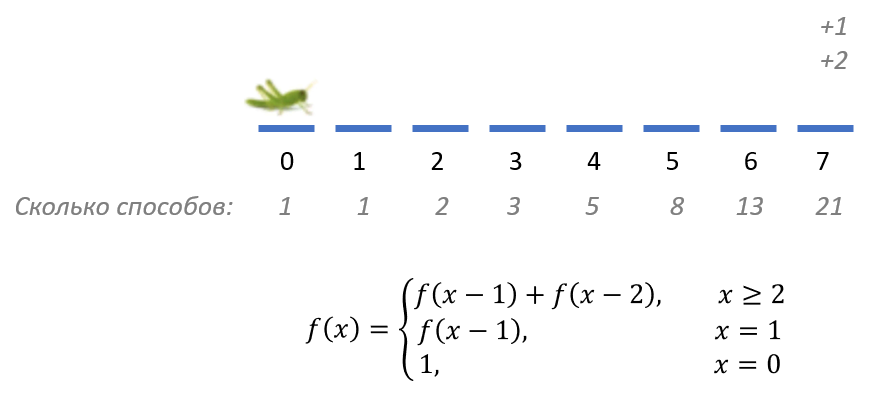

In [11]:
n = int(input())
a = [None] * (n + 1)
a[0] = 1

for i in range(1, n+1):
  if i == 1:
    a[i] = a[0]
  else:
    a[i] = a[i-1] + a[i-2]

print(a[n])

7
21


### Задача: Кузнечик со штрафом (путь минимальной стоимости)

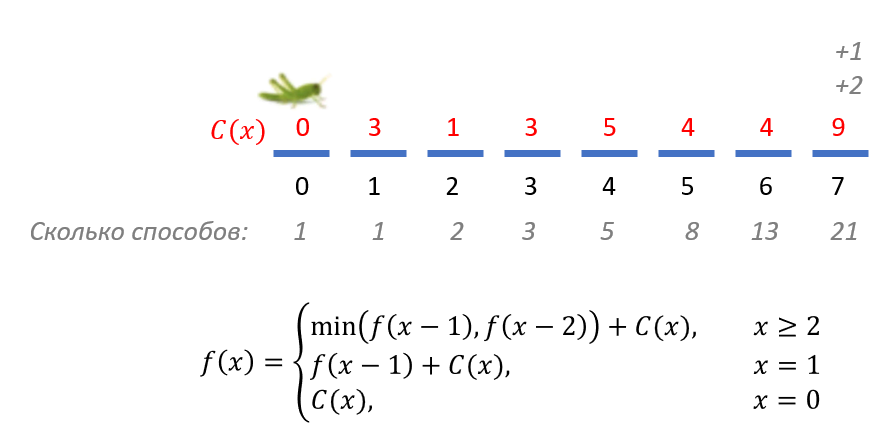

In [13]:
n = int(input()) # число ступенек
c = list(map(int, input().split())) # стоимости
a = [None] * (n + 1)
a[0] = c[0] # суммарная стоимость на i-м шаге

for i in range(1, n + 1):
  if i == 1:
    a[i] = a[i-1] + c[i]
  elif i == 2:
    a[i] = min(a[i-1], a[i-2]) + c[i]
  else:
    a[i] = min(a[i-1], a[i-2], a[i-3]) + c[i]

print(a[n-1])

7
0 3 1 3 5 4 4 9
7


### Восстановление пути***
Храним либо переходы, либо номера платформ, с которых сделали шаг.

***Примечание автора***: (Не уверена, что обязательно нужно это рассказать, но лучше знать!)

In [ ]:
n = int(input())
c = list(map(int, input().split()))
a = [None] * (n)
path = [None] * (n)

# Базовые случаи
a[0] = c[0]
path[0] = -1  # начальная точка

if n > 1:
    a[1] = a[0] + c[1]
    path[1] = 0

for i in range(2, n):
    if a[i-1] < a[i-2]:
        a[i] = a[i-1] + c[i]
        path[i] = i-1
    else:
        a[i] = a[i-2] + c[i]
        path[i] = i-2

print("Min cost:", a[n-1])
print("Path array:", path)

# Восстановление пути
current = n-1
result_path = []
while current >= 0:
    result_path.append(current)
    current = path[current]
result_path.reverse()
print("Path:", result_path)



3
1 1 4
Min cost: 5
Path array: [-1, 0, 0]
Path: [0, 2]


# 5. Базовые структуры данных (массив,список, очередь, стек). Внутреннее устройство и основные операции

### список VS массив:
Список (который list) — универсальная изменяемая последовательность, которая может содержать объекты разных типов. Под «массивом» обычно понимают либо array.array из стандартной библиотеки, либо numpy.ndarray для численных вычислений. У этих типов элементы имеют единый тип хранения, но возможности различаются.





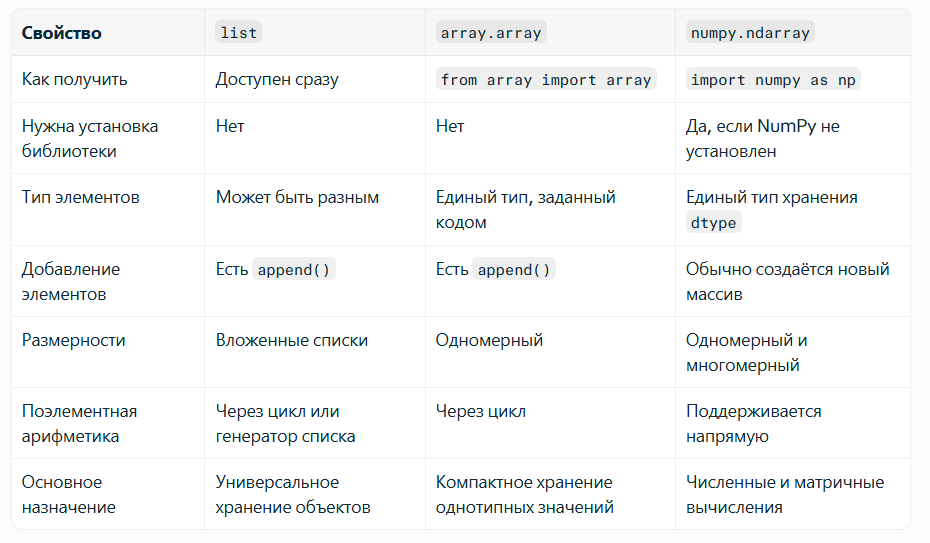

### Массивы (list)
Большинство программ работает не с отдельными переменными, а с набором
переменных. Например, программа может обрабатывать информацию об
учащихся класса, считывая список учащихся с клавиатуры или из файла, при
этом изменение количества учащихся в классе не должно требовать
модификации исходного кода программы.

Для хранения таких данных можно использовать структуру данных,
называемую в Питоне список (в большинстве же языков программирования
используется другой термин --- «массив», разницу мы обсудим позже). Список представляет собой
последовательность элементов, пронумерованных от 0. Список можно задать
перечислением элементов в квадратных скобках, например, список можно
задать так:

``` python
primes = [2, 3, 5, 7, 11, 13]
Rainbow = ['Red', 'Orange', 'Yellow', 'Green', 'Blue', 'Indigo', 'Violet']
```

В списке `primes` --- 6 элементов типа int
Список `rainbow` состоит из 7 элементов, каждый из которых является
строкой.

Также как и символы строки, элементы списка можно индексировать
отрицательными числами с конца, например, `primes[-1] == 13`,
`primes[-6] == 2.`

Длину списка, то есть количество элементов в нем, можно узнать при
помощи функции len, например, `len(A) == 6`.

Рассмотрим несколько способов создания и считывания списков. Пустой,
т.е. не имеющий элементов список, можно создать следующим образом:

``` python
A = []
```

Для добавления элементов в конец списка используется метод `append`.
Если программа получает на вход количество элементов в списке `n`, а
потом `n` элементов списка по одному в отдельной строке, то организовать
считывание списка можно так:

``` python
A = []
for i in range(int(input()):
    A.append(int(input())
```

В этом примере создается пустой список, далее считывается количество
элементов в списке, затем по одному считываются элементы списка и
добавляются в его конец.

Для списков целиком определены следующие операции: конкатенация списков
(добавление одного списка в конец другого) и повторение списков
(умножение списка на число). Например:

``` python
A = [1, 2, 3]
B = [4, 5]
C = A + B
D = B * 3
```

В результате список `C` будет равен `[1, 2, 3, 4, 5]`, а список `D`
будет равен `[4, 5, 4, 5, 4, 5]`. Это позволяет по-другому организовать
процесс считывания списков: сначала считать размер списка и создать
список из нужного числа элементов, затем организовать цикл по переменной
`i` начиная с числа 0 и внутри цикла считывается `i`-й элемент списка:

``` python
A = [0] * int(input())
for i in range(len(A)):
    A[i] = int(input())
```

Вывести элементы списка `A` можно одной инструкцией `print(A)`, при этом
будут выведены квадратные скобки вокруг элементов списка и запятые между
элементами списка. Такой вывод неудобен, чаще требуется просто вывести
все элементы списка в одну строку или по одному элементу в строке.
Приведем два примера, также отличающиеся организацией цикла:

``` python
for i in range(len(A)):
    print(A[i])
```

Здесь в цикле меняется индекс элемента `i`, затем выводится элемент
списка с индексом `i`.

``` python
for elem in A:
    print(elem, end = ' ')
```

В этом примере элементы списка выводятся в одну строку, разделенные
пробелом, при этом в цикле меняется не индекс элемента списка, а само
значение переменной. Например, в цикле
`for elem in ['red', 'green', 'blue']` переменная `elem` будет
последовательно принимать значения \'red\', \'green\', \'blue\'.

Внутри одного списка могут быть любые объекты (и даже вперемешку),
поэтому такая конструкция как список списков вполне осмысленна (аналог
двумерного массива). Обращаться к элементам внутри такого списка нужно
так `A[i][j]` , где `j` - индекс внутри внутреннего списка, `i` - индекс
внутри внешнего списка.

(1) Генерация массива из нулей

In [ ]:
n = int(input())
a = [0] * n # [0, 0, 0]
print(a)
for x in range(n):
  a[x] = input()

print(a)

3
[0, 0, 0]
1
3
5
['1', '3', '5']


(2) Создание массива из строки

In [ ]:
s = input().split(';')
print(s)
for i in range(len(s)):
  s[i] = int(s[i])

print(s)

1;3;4
['1', '3', '4']
[1, 3, 4]


(3) Функция map

In [ ]:
s = ['2', '3']
s = list(map(float, s))

print(s)

[2.0, 3.0]


(4) Добавление элементов

In [ ]:
s.append(4)
print(s)

[2.0, 3.0, 4]


(5) Удаление элемента (с конца)

In [ ]:
s_last = s.pop()
print(s_last)
print(s)

4
[2.0, 3.0]


Если хотим извлечь конкретный элемент, то в () ставим его номер.


In [ ]:
s.pop(1)

3.0

(6) Добавление элемента на определённое место

a.insert(position, element)

In [ ]:
a = [4, 6, 7]
a.insert(1, 5)

print(a)

[4, 5, 6, 7]


In [ ]:
a[1] = 2 #замена

In [ ]:
a.insert(3, 7)

print(a)

[4, 5, 6, 7, 7]


In [ ]:
a.reverse() #аналогично a = a[::-1]

print(a)

[4, 5, 6, 7, 7]


In [ ]:
b = [0, -1, -100, 15, 8]
b.sort()

print(b)

[-100, -1, 0, 8, 15]


(7)*** Более сложный способ заполнить/сгенерировать массив => списковое включение/List Comprehensions

In [ ]:
a = []
for i in range(10):
  a.append(i)

print(a)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [ ]:
a = [i for i in range(10)]

print(a)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [ ]:
a = [i**i for i in range(1, 10)]

print(a)

[1, 4, 27, 256, 3125, 46656, 823543, 16777216, 387420489]


In [ ]:
a = [i for i in range(10) if i % 2 != 0]
b = [i for i in range(10) if i % 2 == 0]
print(a)
print(b)

[1, 3, 5, 7, 9]
[0, 2, 4, 6, 8]


In [ ]:
def f(x):
  return x**2

In [ ]:
s1 = list(map(f, range(10))) #1
s2 = list(map(lambda x: x**2, range(10))) #2
s3 = [i**2 for i in range(10)] #3
s4 = []
for i in range(10):
  s4.append(i**2)

print(s1)
print(s2)
print(s3)
print(s4)

[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]


(8) Срезы

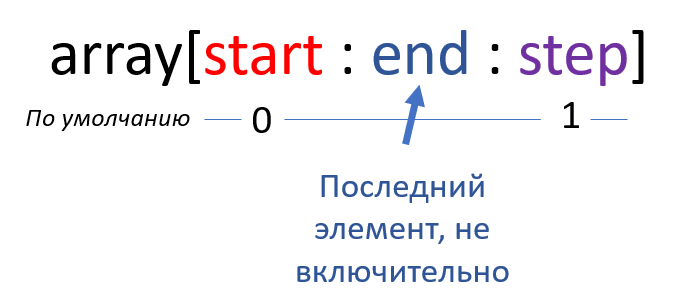

In [ ]:
a = [4, 5, 7, 6, 3]

print(a[1:3])
print(a[::-1])


[5, 7]
[3, 6, 7, 5, 4]


### Пример: поиск суммы чётных положительных элементов в массиве

In [ ]:
n = int(input())
a = [int(input()) for _ in range(n)]
s = 0

for e in a:
  if e > 0 and e % 2 == 0:
    s += e
print(s)

4
2
4
8
10
24


(8) Можно пройтись и по объектам массива, и по номерам

In [ ]:
a = 'psppspsppsps'

for i, e in enumerate(a):
  print(i, e)


0 p
1 s
2 p
3 p
4 s
5 p
6 s
7 p
8 p
9 s
10 p
11 s


In [ ]:
a = 'psppspsppsps'
b = '546474848484'

for x,y in zip(a,b):
  print(x, y)

p 5
s 4
p 6
p 4
s 7
p 4
s 8
p 4
p 8
s 4
p 8
s 4


Summary:

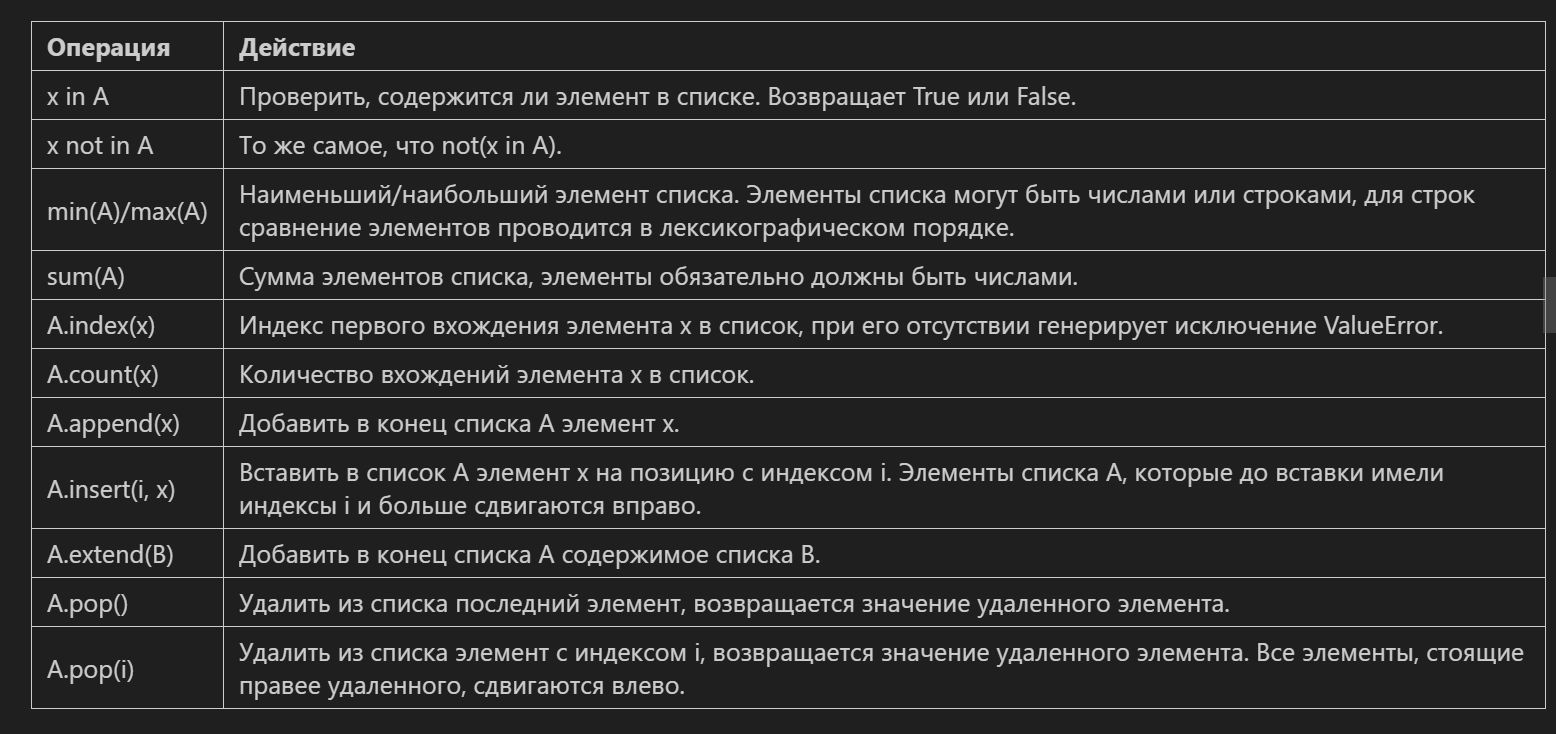

In [ ]:
A = [1, 7, 8]
B = [9, 10]

C = A + B
print(C)
A.extend(B)
print(A)

[1, 7, 8, 9, 10]
[1, 7, 8, 9, 10]


### Список
Под «списком» могут иметь в виду динамический массив (как list в Python) или связный список; в базовом курсе чаще говорят о связанном списке.​

Внутреннее устройство (односвязный список):

* Структура состоит из узлов (node).

* Каждый узел хранит: данные и ссылку (указатель) на следующий узел.

* Храним указатель на «голову» списка; элементы в памяти могут лежать не подряд.​

Основные операции:

* Вставка в начало: создать узел, его $next$ указывает на старую голову, голова сдвигается на новый узел — $O(1)$.

* Вставка/удаление в середине: нужно сначала дойти до нужного места — $O(n)$.

* Поиск по значению или индексу — последовательный проход, $O(n)$.​

Плюс связных списков — дёшево вставлять/удалять элементы, не двигая остальные. Минус — медленный произвольный доступ (нет $O(1)$ по индексу)

In [ ]:
class Box:
  def __init__ (self,cat = None):
    self.cat = cat
    self.nextcat = None

class LinkedList:
  def __init__(self):
    self.head = None

  def contains(self, cat):
    lastbox = self.head
    while (lastbox):
      if cat == lastbox.cat:
        return True
      else:
        lastbox = lastbox.nextcat
    return False

  def addToEnd(self, newcat):
    newbox = Box(newcat)
    if self.head is None:
      self.head = newbox
      return
    lastbox = self.head
    while (lastbox.nextcat):
        lastbox = lastbox.nextcat
    lastbox.nextcat = newbox


  def get(self, catIndex):
    lastbox = self.head
    boxIndex = 0
    while boxIndex <= catIndex:
      if boxIndex == catIndex:
          return lastbox.cat
      boxIndex = boxIndex + 1
      lastbox = lastbox.nextcat

  def removeBox(self,rmcat):
    headcat = self.head

    if headcat is not None:
      if headcat.cat==rmcat:
        self.head = headcat.nextcat
        headcat = None
        return
    while headcat is not None:
      if headcat.cat==rmcat:
        break
      lastcat = headcat
      headcat = headcat.nextcat
    if headcat == None:
      return
    lastcat.nextcat = headcat.nextcat
    headcat = None

  def LLprint(self):
    currentCat = self.head
    print("LINKED LIST")
    print("-----")
    i = 0
    while currentCat is not None:
      print (str(i) + ": " + str(currentCat.cat))
      i += 1
      currentCat = currentCat.nextcat
    print("-----")

### Стек (Stack)
Стек - структура данных LIFO (Last-In-First-Out), где элементы добавляются и удаляются с одного конца (вершины).

Основные операции:

* push(x) - добавить элемент на вершину

* pop() - удалить и вернуть верхний элемент

* peek() - посмотреть верхний элемент без удаления

* is_empty() - проверка на пустоту

Все эти операции в нормальной реализации работают за $O(1)$. Стек используют для: обратного обхода (рекурсия/эмуляция стека вызовов), отмены действий (undo), проверки скобок, обхода графов (DFS) и т.п.

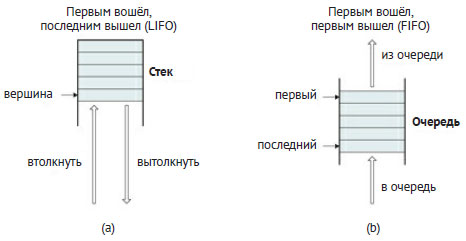

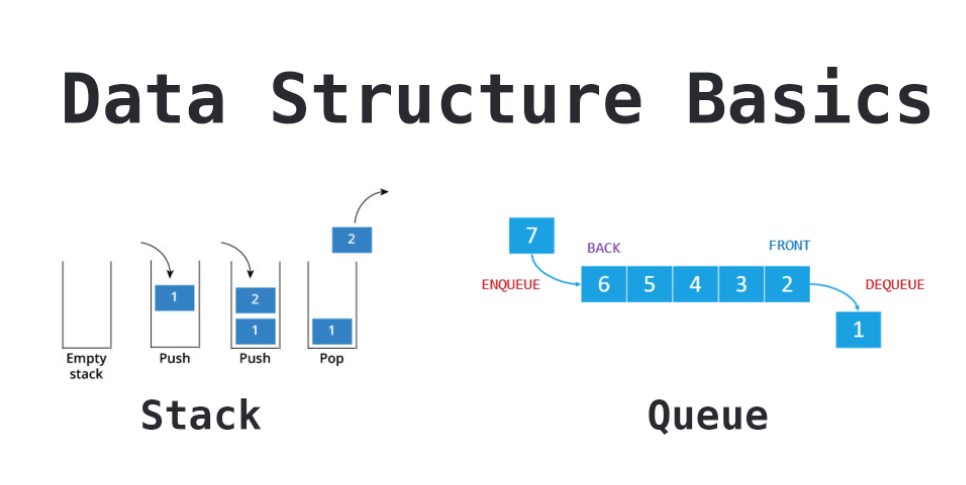

In [ ]:
class Stack:
    def __init__(self):
        self.items = []

    def push(self, item):
        """Добавление элемента на вершину стека"""
        self.items.append(item)

    def pop(self):
        """Удаление и возврат верхнего элемента"""
        if not self.is_empty():
            return self.items.pop()
        raise IndexError("pop from empty stack")

    def peek(self):
        """Просмотр верхнего элемента без удаления"""
        if not self.is_empty():
            return self.items[-1]
        raise IndexError("peek from empty stack")

    def is_empty(self):
        """Проверка на пустоту"""
        return len(self.items) == 0

    def size(self):
        """Размер стека"""
        return len(self.items)

    def __str__(self):
        return f"Stack({self.items})"

# Пример использования
stack = Stack()
stack.push(1)
stack.push(2)
stack.push(3)
print(stack)  # Stack([1, 2, 3])
print(stack.pop())  # 3
print(stack.peek())  # 2
print(stack.is_empty())  # False

Stack([1, 2, 3])
3
2
False


### Очередь (Queue)
Очередь - структура данных FIFO (First-In-First-Out), где элементы добавляются в конец и удаляются из начала.

Основные операции:

* enqueue(x) / push  - добавить элемент в конец

* dequeue() / pop- удалить и вернуть первый элемент

* front() / peek - посмотреть первый элемент

* is_empty() - проверка на пустоту

При корректной реализации все операции очереди тоже выполняются за $O(1)$. Очередь используют там, где важен естественный порядок обработки: очереди задач, обработка событий, обход графа в ширину (BFS), планирование процессов и т.п.

In [ ]:
class Queue:
    def __init__(self):
        self.items = []

    def enqueue(self, item):
        """Добавление элемента в конец очереди"""
        self.items.append(item)

    def dequeue(self):
        """Удаление и возврат первого элемента"""
        if not self.is_empty():
            return self.items.pop(0)
        raise IndexError("dequeue from empty queue")

    def front(self):
        """Просмотр первого элемента без удаления"""
        if not self.is_empty():
            return self.items[0]
        raise IndexError("front from empty queue")

    def is_empty(self):
        """Проверка на пустоту"""
        return len(self.items) == 0

    def size(self):
        """Размер очереди"""
        return len(self.items)

    def __str__(self):
        return f"Queue({self.items})"

# Пример использования
queue = Queue()
queue.enqueue(1)
queue.enqueue(2)
queue.enqueue(3)
print(queue)  # Queue([1, 2, 3])
print(queue.dequeue())  # 1
print(queue.front())    # 2
print(queue.size())     # 2

Queue([1, 2, 3])
1
2
2


# 6. Простые сортировки (пузырьковая, вставками, выбором– реализация на выбор). Обоснование асимптотики. Устойчивость сортировок.

***Примечание автора***: здесь часто говорим про оценку ассимптотики в худшем, лучше и среднем случаях - подробнее можно почитать про все 3 вида в будущем семинаре №10: https://github.com/ScarrryMary/IT_MIPT_group25-26/blob/main/Seminar_10_25_26.ipynb

### Сортировка пузырьком  

Проходит по массиву многократно, сравнивая соседние элементы и меняя их местами, если они в неверном порядке; после первого полного прохода «всплывает» максимальный элемент в конец, затем процесс повторяют для сокращённой части массива

In [14]:
def bubble_sort(a):
  n = len(a)
  for i in range(n):
    for j in range(n-i-1):
      if a[j] > a[j+1]:
        a[j], a[j+1] = a[j+1], a[j]

a = [15, -6, 3, 14, -23, 3, 12]
bubble_sort(a)
print(a)

[-23, -6, 3, 3, 12, 14, 15]


* Лучший случай: $O(n)$ - когда массив уже отсортирован

* Средний и худший случай: $O(n^2)$

* Память: $O(1)$ (сортировка на месте)

* Устойчивость: Сохраняет порядок равных элементов

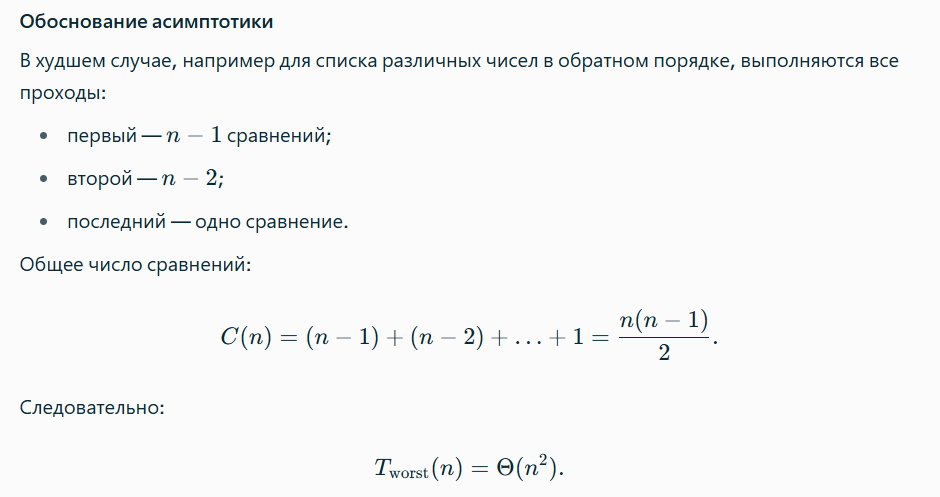

### Сортировка вставками (Insertion Sort).
Проходит слева направо, на каждом шаге берёт следующий элемент и «вставляет» его в уже отсортированную левую часть, сдвигая большие элементы вправо, пока не найдёт нужную позицию.

In [ ]:
def insertion_sort(a):
  n = len(a)
  for i in range(1, n):
    for j in range(i, 0, -1):
      if a[j] < a[j-1]:
        a[j], a[j-1] = a[j-1], a[j]

a = [15, -6, 3, 14, -23, 3, 12]
insertion_sort(a)
print(a)

Ещё пример:
```python
Начало:       [5, 3, 4, 1, 2]
Вставляем 3:  [3, 5, 4, 1, 2]
Вставляем 4:  [3, 4, 5, 1, 2]
Вставляем 1:  [1, 3, 4, 5, 2]
Вставляем 2:  [1, 2, 3, 4, 5]
```
После обработки позиции i часть списка $a[0:i + 1]$ отсортирована. Это инвариант алгоритма: каждое следующее вставление увеличивает отсортированную часть на один элемент.



Как работает алгоритм:

1) Начинаем со второго элемента (i = 1)

2) Для каждого элемента "проталкиваем" его влево, пока он не займет правильную позицию в отсортированной части

3) Повторяем для всех элементов массива


* Лучший случай: $O(n)$ - когда массив уже отсортирован

* Средний и худший случай: $O(n^2)$

* Память: $O(1)$ (сортировка на месте)

* Устойчивость: Сохраняет порядок равных элементов

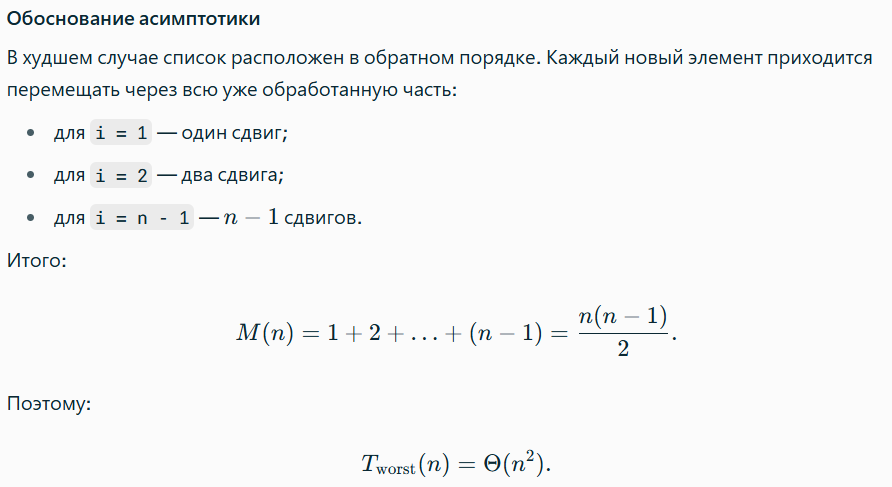

### Сортировка выбором (Selection Sort).
На i‑м шаге ищет минимальный элемент в неотсортированной части и меняет его местами с элементом на позиции i; затем переходит к i+1 и т.д.

После первого шага на позиции 0 находится минимум всего списка. После второго на позиции 1 — минимум оставшейся части, и так далее.

In [ ]:
def selection_sort(a):
  n = len(a)
  for i in range(n-1):
    k = i
    for j in range(i+1, n):
      if a[j] < a[k]:
        k = j
    a[k], a[i] = a[i], a[k]

a = [15, -6, 3, 14, -23, 3, 12]
selection_sort(a)
print(a)

[-23, -6, 3, 3, 12, 14, 15]


Как работает алгоритм:

1) Находим минимальный элемент в неотсортированной части массива

2) Меняем его с первым элементом неотсортированной части

3) Увеличиваем границу отсортированной части на 1 элемент

4) Повторяем до полной сортировки

* Сложность: $O(n^2)$ в лучшем, среднем и худшем случаях

* Память: $O(1)$ (сортировка на месте)

* Неустойчивость: Может менять порядок равных элементов

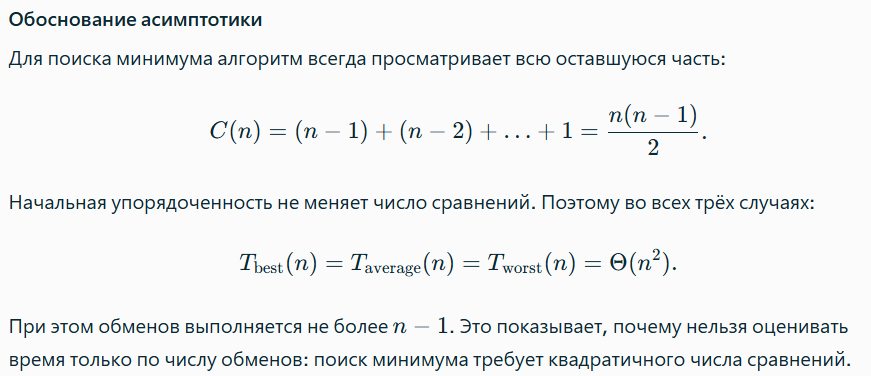

***Примечание автора***: Вот подробнее про устойчивость сортировок из лекций:

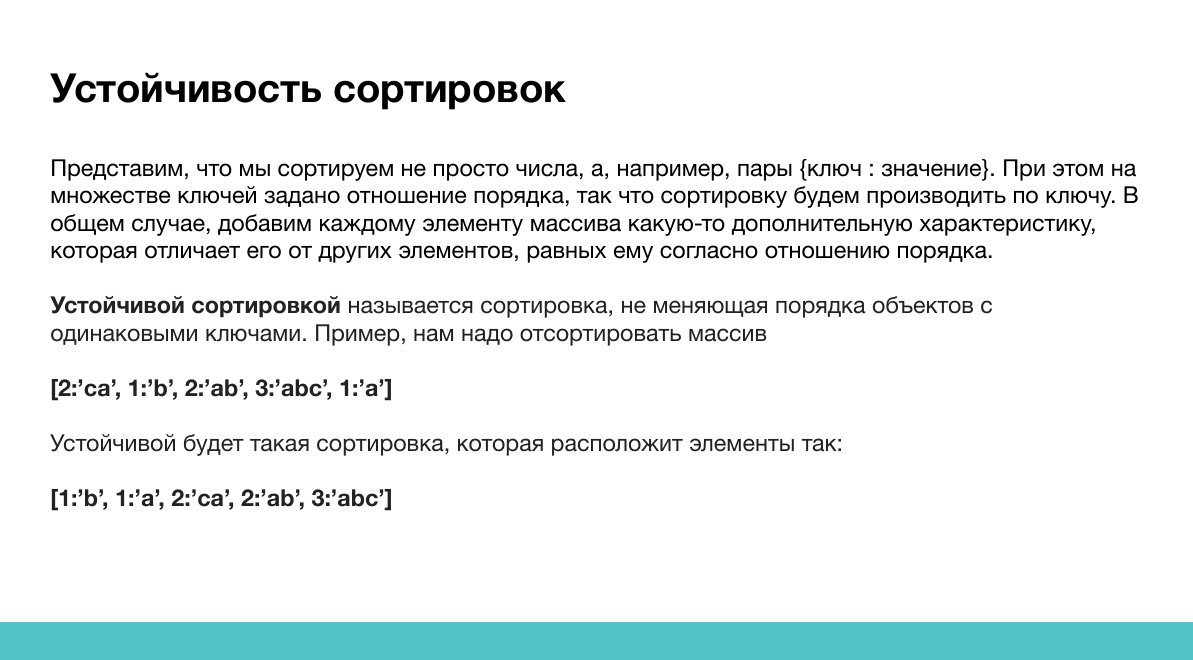

https://habr.com/ru/companies/kts/articles/727528/ - хорошая статья с визуализацией, советую!

# 7. Динамическое программирование. Расстояние Левенштейна

Дальше следует материал по классной статье: https://habr.com/ru/articles/676858/?ysclid=mh3mcxqbt517896452

**Расстояние Левенштейна**, или **редакционное расстояние**, — метрика cходства между двумя строковыми последовательностями. Чем больше расстояние, тем более различны строки. Для двух одинаковых последовательностей расстояние равно нулю. По сути, это минимальное число односимвольных преобразований (удаления, вставки или замены), необходимых, чтобы превратить одну последовательность в другую.

Например, $LEV(’БИБА’, ‘БОБА’) = 1$, так как потребуется провести одну замену $‘И’$ на $‘О’$.

Расстояние Левенштейна активно используется для исправления ошибок в словах, поиска дубликатов текстов, сравнения геномов и прочих полезных операций с символьными последовательностями.

> Метрика названа в честь советского математика, выпускника мехмата МГУ Владимира Иосифовича Левенштейна. Он всю жизнь проработал в Институте Прикладной Математики им. М.В.Келдыша, умер в 2017 году.


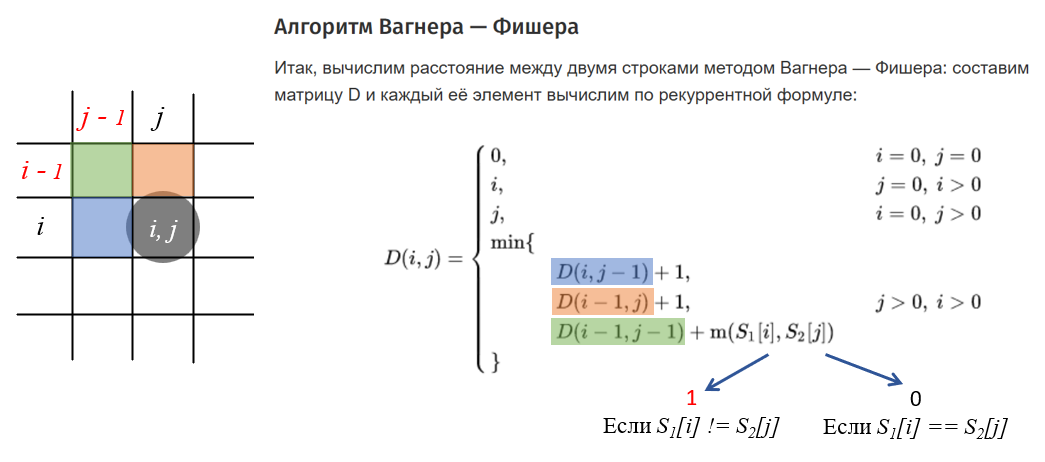

Ясно, что первые три строчки рекуррентной формулы помогут нам заполнить только первый столбец и первую строку таблицы. Для всех остальных ячеек мы будем пользоваться четвёртой строкой — той, что с минимумом. Здесь $S_1[i], S_2[j]$— символы, соответствующие ячейкам i и j. Оператор $m(S_1[i],S_2[j]) = 1$,если символы $S_1[i]$ и $S_2[i]$ не равны друг другу, и $m(S_1[i],S_2[j]) = 0$, если равны.

Обратите внимание, что первый символ последовательности будет иметь индекс 1, как принято в математике, а не 0.

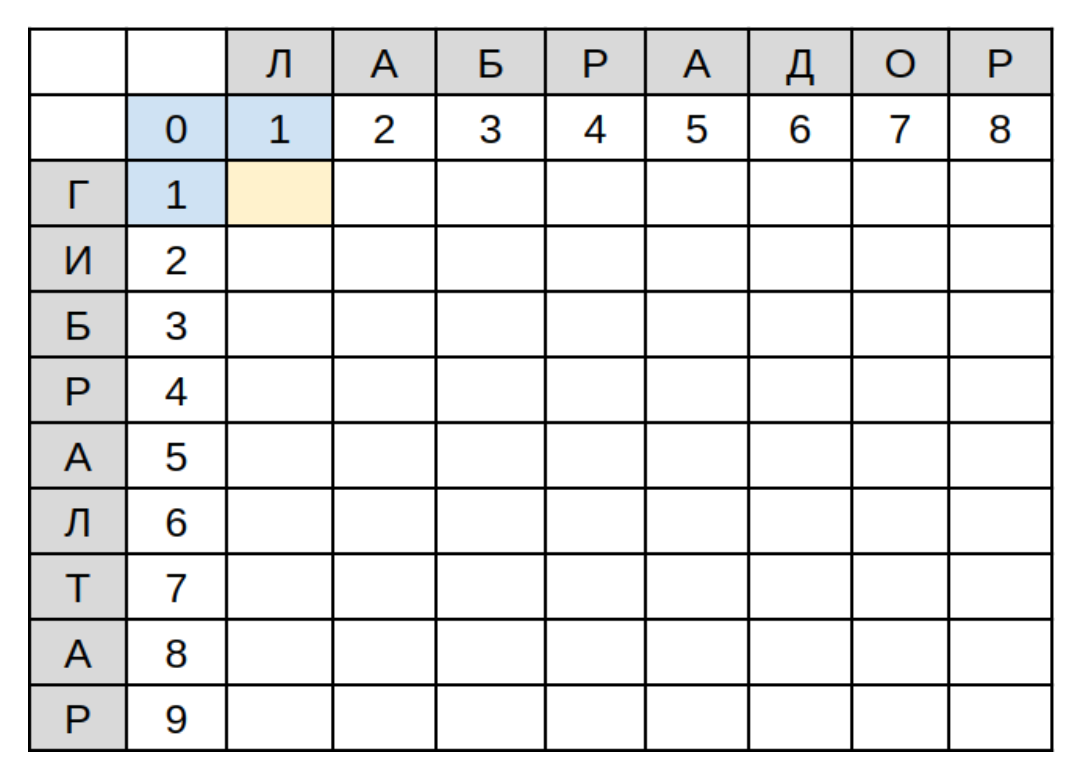

Рассчитаем D(1,1), это символы ‘Г’ и ‘Л’. Они не равны друг другу, значит m(’Г’, ‘Л’) = 1. Тогда D(1,1) — это минимум между значениями D(0,1) + 1, D(1,0) + 1 и D(0, 0) + m(’Г’, ‘Л’) = D(0, 0) + 1. Эти клетки выделены голубым. То есть min(1+1, 1+1, 0+1) = min(2, 2, 1) = 1.

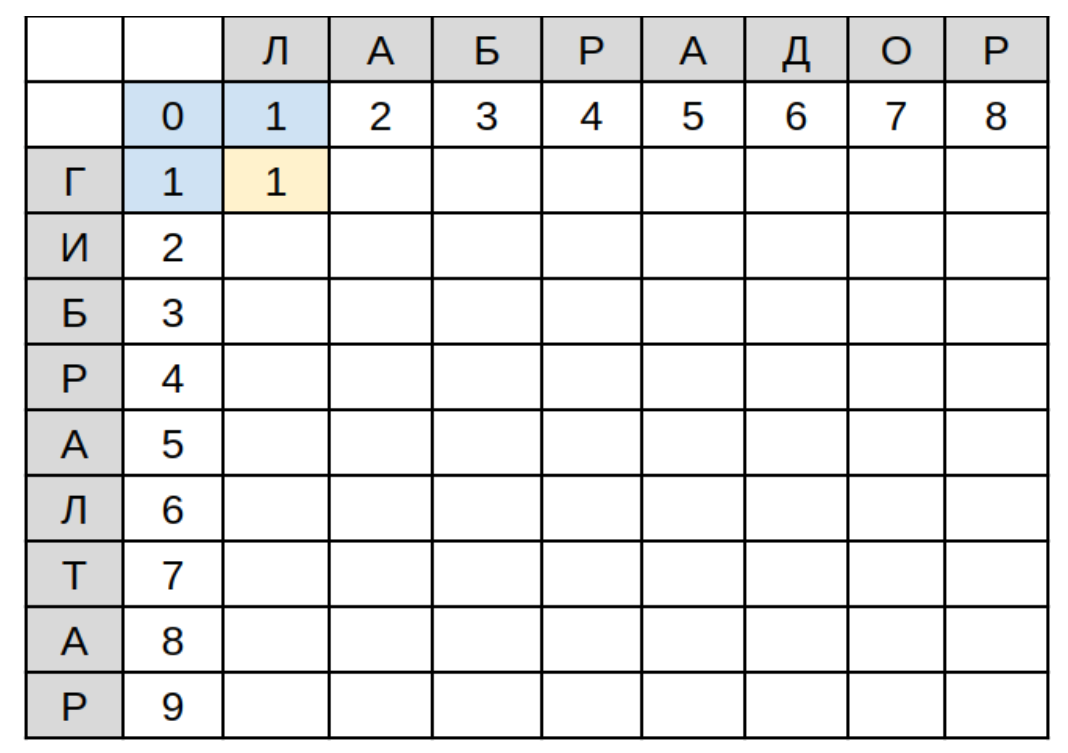

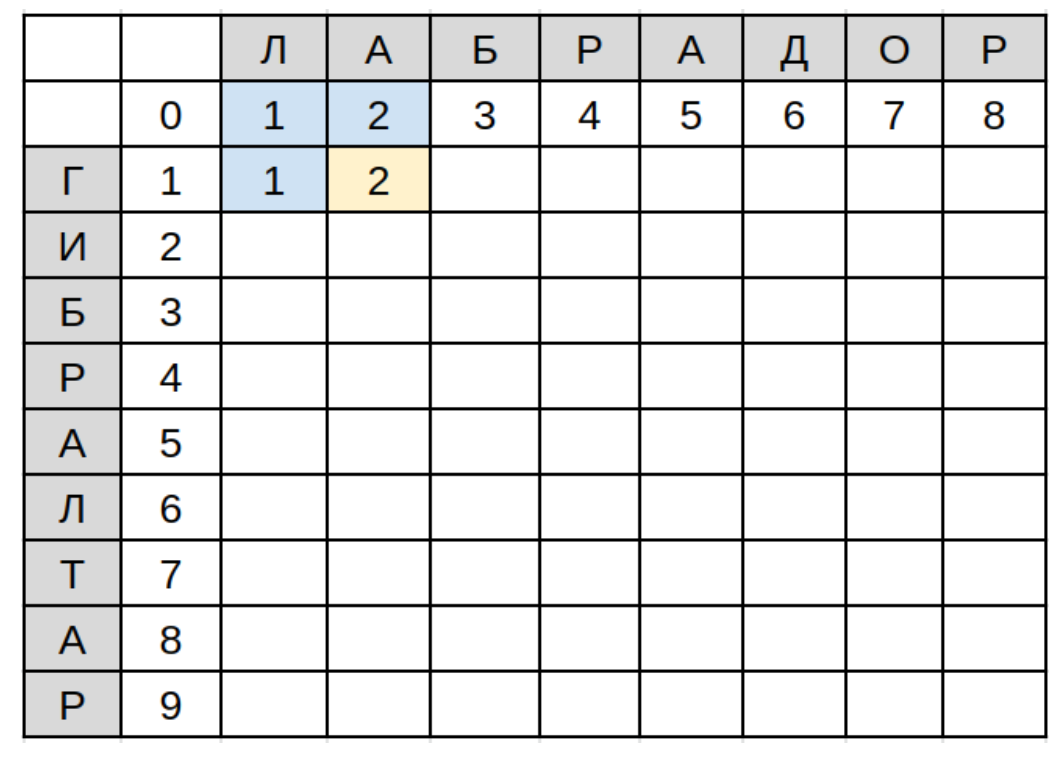

Передвигая голубой уголок, аналогично заполним первые две строки и начало третьей, пока не доберёмся до совпадающих символов ‘Б’ в D(3,3):

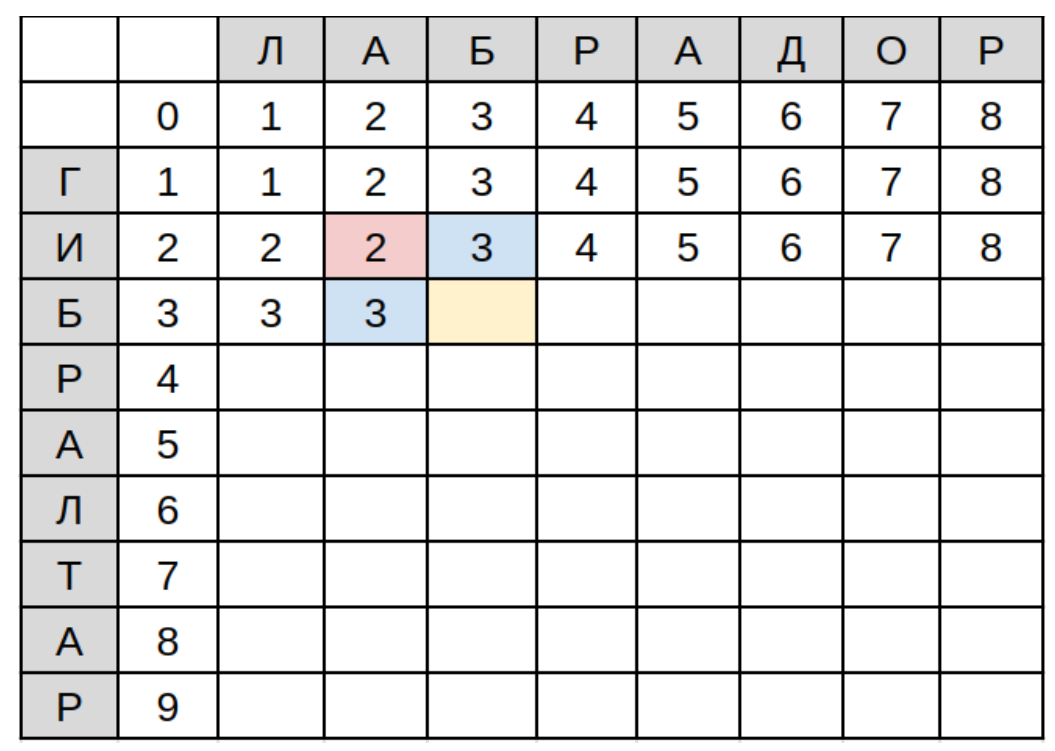

Из-за того, что символы совпадают, замена этим двум символам не нужна, поэтому при подсчёте минимума число в розовой ячейке не увеличивается на единицу, т.е. D(3, 3) = min(D(2,3) + 1; D(3,2) + 1; D(2, 2) + 0) = min(3+1; 3+1; 2+0) = 2.

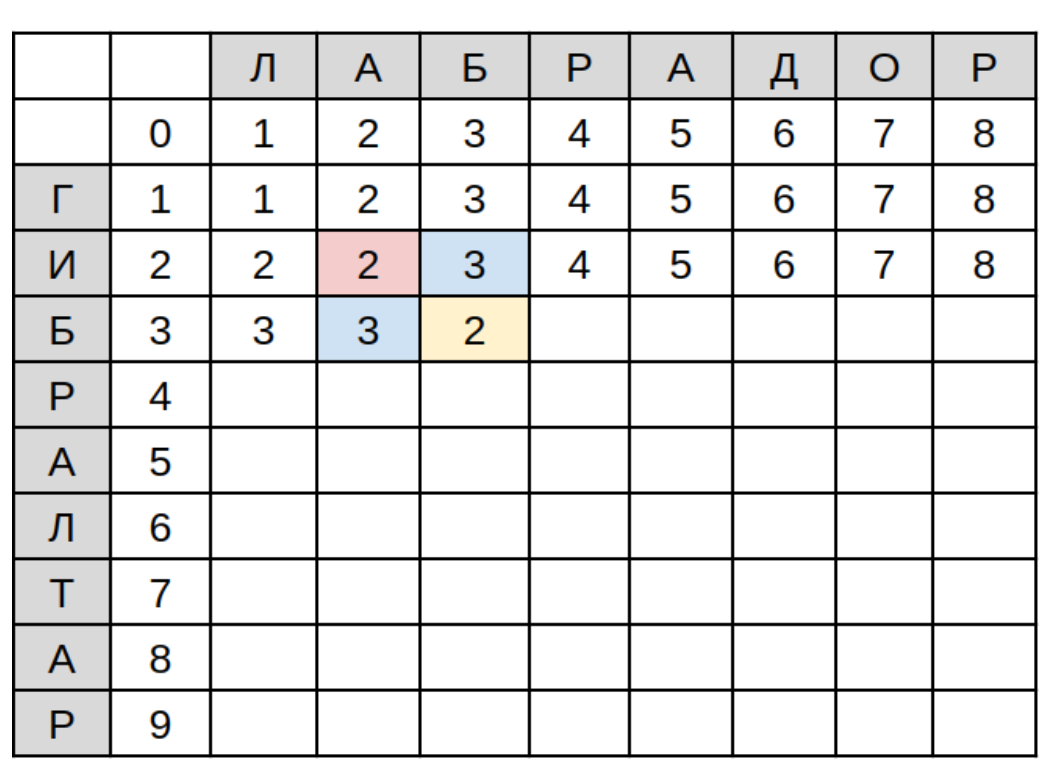

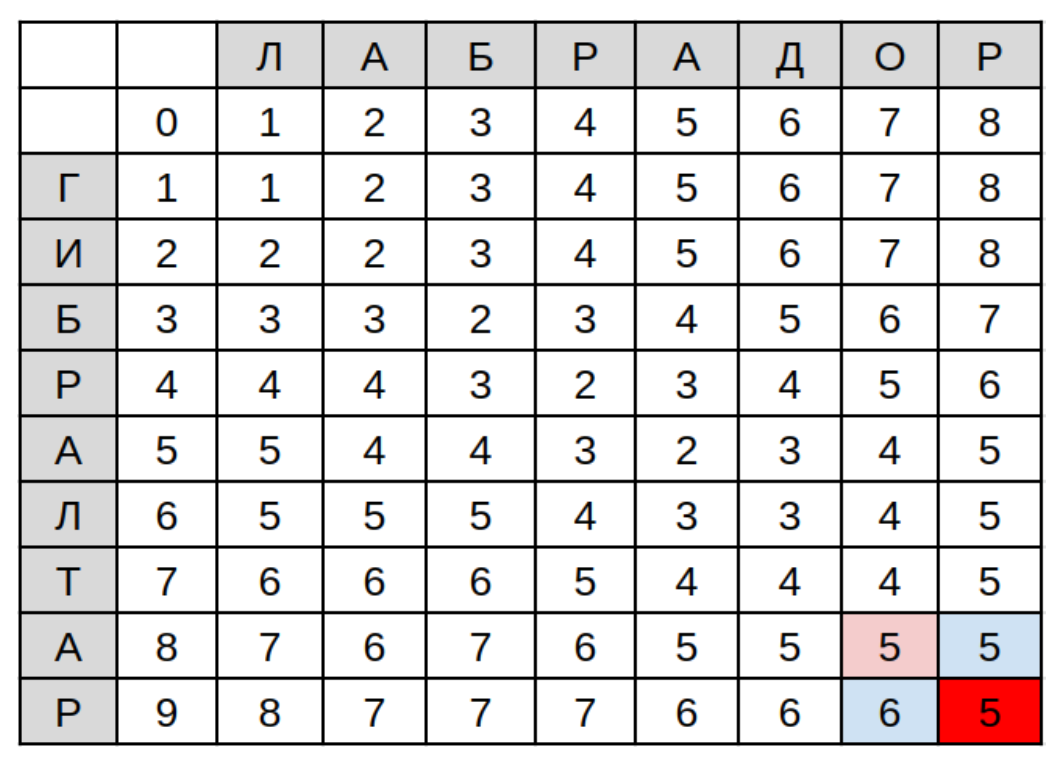

In [ ]:
def levenstein(str_1, str_2):
    n, m = len(str_1), len(str_2)
    if n > m:
        str_1, str_2 = str_2, str_1
        n, m = m, n

    current_row = range(n + 1)
    for i in range(1, m + 1):
        previous_row, current_row = current_row, [i] + [0] * n
        for j in range(1, n + 1):
            add, delete, change = previous_row[j] + 1, current_row[j - 1] + 1, previous_row[j - 1]
            if str_1[j - 1] != str_2[i - 1]:
                change += 1
            current_row[j] = min(add, delete, change)

    return current_row[n]

str_1 = "кот"
str_2 = "скат"
print(levenstein(str_1, str_2))

2


# 8. Динамическое программирование. Наибольшая общая подпоследовательность.

Пусть есть две последовательности (обычно строки) $X$ и $Y$.
Подпоследовательность — это элементы, взятые из исходной последовательности в том же порядке, но возможно с пропусками.​
Наибольшая общая подпоследовательность (НОП, LCS - Longest Common Subsequence) — общая подпоследовательность $X$ и $Y$ максимальной длины.​

Пример:
$X = "abcabaac"$, $Y = "baccbca"$. Одна из LCS: "baba" или "babc" (длина 4).


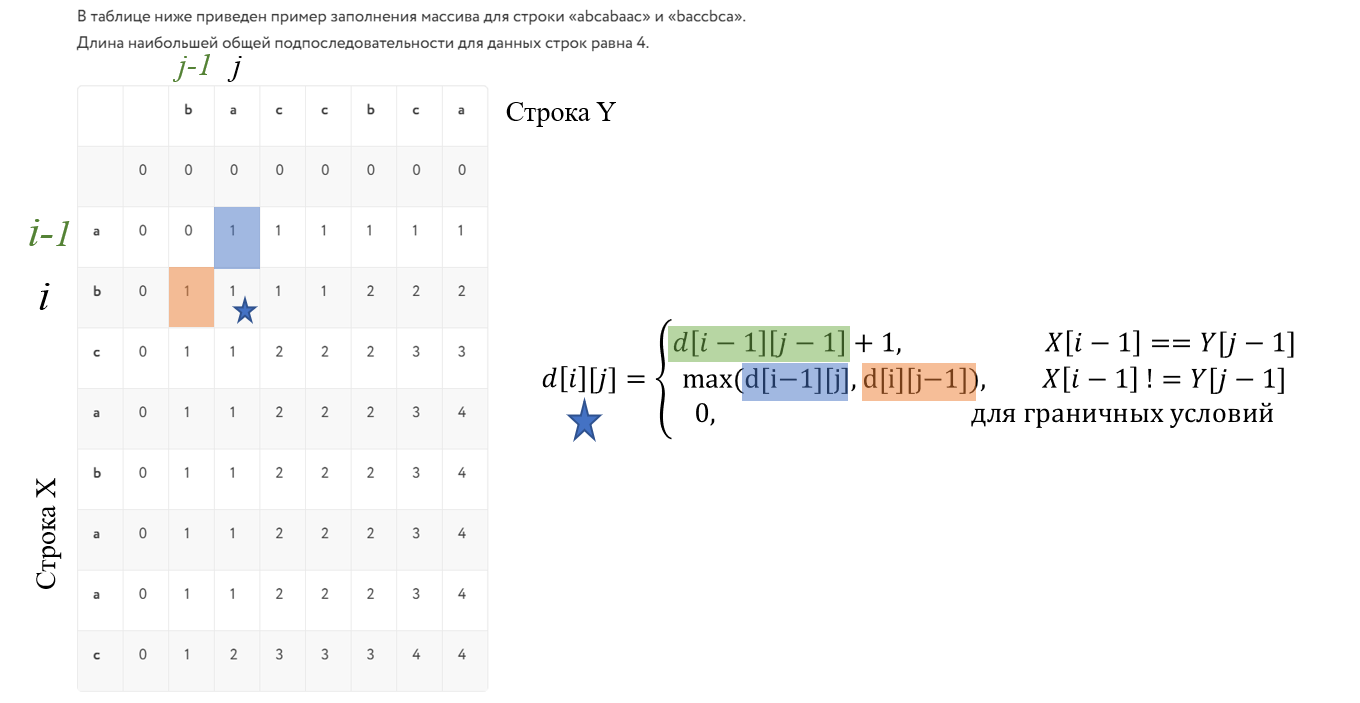

Рассматриваются префиксы строк: $X[0..i−1]$ и $Y[0..j−1]$. Вводится функция $d[i][j]$ — длина LCS для этих двух префиксов.​

Рекуррентные соотношения:

* Если последние символы совпадают:
$X[i−1]=Y[j−1]$, то $d[i][j]=d[i−1][j−1]+1$
потому что к LCS префиксам (без этих символов) можно добавить этот общий символ.​

* Если не совпадают: $d[i][j]=max(d[i−1][j],d[i][j−1])$
либо отбрасываем последний символ X, либо Y, выбирая лучший вариант.​

Базовые случаи:
* Если хотя бы одна строка пустая ($i=0$ или $j=0$), то LCS имеет длину 0: $d[i]=d[j]=0$.​

In [ ]:
def lcs(a, b):
    n = len(a)
    m = len(b)

    d = [[0] * (m + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if a[i-1] == b[j-1]:
                d[i][j] = d[i-1][j-1] + 1
            else:
                d[i][j] = max(d[i-1][j], d[i][j-1])

    return d

a = list(map(int, input().split()))
b = list(map(int, input().split()))
d = lcs(a, b)

for line in d:
  print(*line)

1 2 3 4
2 4 1 3
0 0 0 0 0
0 0 0 1 1
0 1 1 1 1
0 1 1 1 2
0 1 2 2 2


**Табличное решение** (снизу вверх)  
Строится таблица размеров $(n+1)×(m+1)$, где $n = |X|$, $m = |Y|$. ​

* Инициализируем первую строку и первый столбец нулями (пустой префикс).

* Заполняем d по строкам или по столбцам согласно формулам выше.​


**Пример направления заполнения и логики**:

* Если символы равны, берём диагональ + 1 (верх-лево),

* Иначе — максимум из «сверху» и «слева».​

Ответ: длина LCS — это значение в правом нижнем углу таблицы: $d[n][m]$.​

**Восстановление самой подпоследовательности**  
Чтобы получить не только длину, но и саму LCS, после заполнения таблицы двигаются от клетки d[n][m] к dp:​

* Если $X[i−1]=Y[j−1]$, этот символ входит в LCS: добавляем его в результат и идём по диагонали $(i–1, j–1)$.

* Иначе смотрим, откуда пришёл максимум:

* * если $d[i−1][j]>d[i][j−1]$, идём вверх ($i–1$, $j$),

* * иначе — влево ($i$, $j–1$).

Собранная последовательность получается в обратном порядке, поэтому её разворачивают

**Сложность**  

**Время**: $O(n·m)$, так как заполняется вся таблица размером $n×m$.​

**Память**: $O(n·m)$ при хранении всей таблицы; можно оптимизировать до $O(min(n,m))$ для вычисления только длины, используя две строки (текущую и предыдущую)

# 9. Динамическое программирование. Наибольшая возрастающая подпоследовательность.

== longest increasing subsequence

Наибольшая возрастающая подпоследовательность (LIS)

**Условие**: дана последовательность чисел $a[0..n−1]$. Найти длину самой длинной строго возрастающей подпоследовательности (не обязательно непрерывной).

In [1]:
def lis(n, a):
  d = [1] * n
  for i in range(1, n):
      for j in range(i):
          if a[j] < a[i]:
              d[i] = max(d[i], d[j] + 1)
  return d

n = int(input())
a = list(map(int, input().split()))
print(*lis(n, a))

8
10 9 2 5 3 7 101 8
1 1 1 2 2 3 4 4


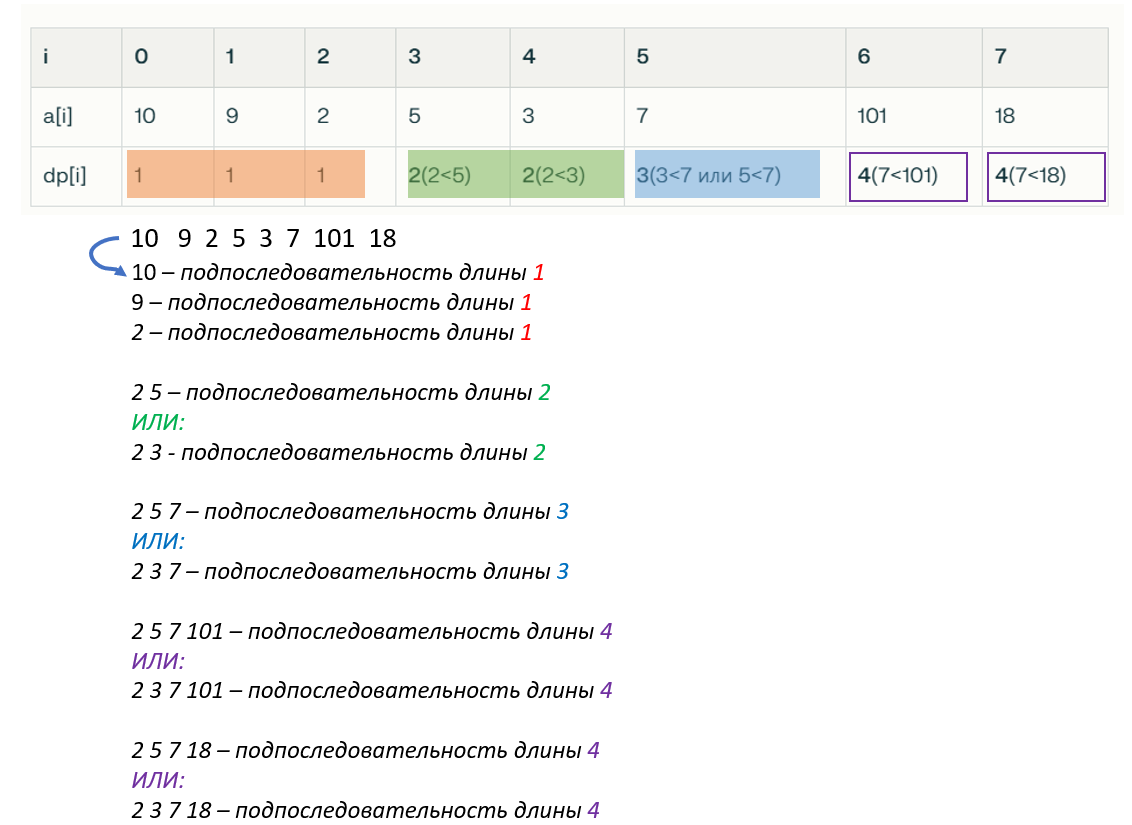

**Сложность**
* Время: $O(n^2)$ — два вложенных цикла.

* Память: $O(n)$ для d.

Оптимизация: существует $O(n log n)$ алгоритм с использованием бинарного поиска (храним минимальные хвосты подпоследовательностей каждой длины), но базовый ДП проще понять

**Восстановление самой подпоследовательности**   
Чтобы найти не только длину, но и саму LIS, хранят дополнительный массив prev[i] — индекс предыдущего элемента для d[i]. После нахождения позиции максимума d[k] идут по prev назад и собирают последовательность в обратном порядке.

# 10. Динамическое программирование. Задача о рюкзаке.

Задача о рюкзаке (Knapsack Problem) — классическая задача комбинаторной оптимизации: есть рюкзак вместимостью $W$ и $n$ предметов с весами $w[i]$ и стоимостями $v[i]$. Нужно выбрать подмножество предметов (каждый либо берётся целиком, либо нет), чтобы максимизировать суммарную стоимость при весе $≤ W$.

**Формулировка динамического программирования**  
Пусть $dp[i][w]$ — максимальная стоимость, которую можно получить, используя первые $i$ предметов с общим весом $≤ w$.

Базовые случаи:
* $dp[w]=0$ для всех $w$ (нет предметов — стоимость 0).
* $dp[i]=0$ (вес 0 — ничего не берём).​

Ответ лежит в $dp[n][W]$.

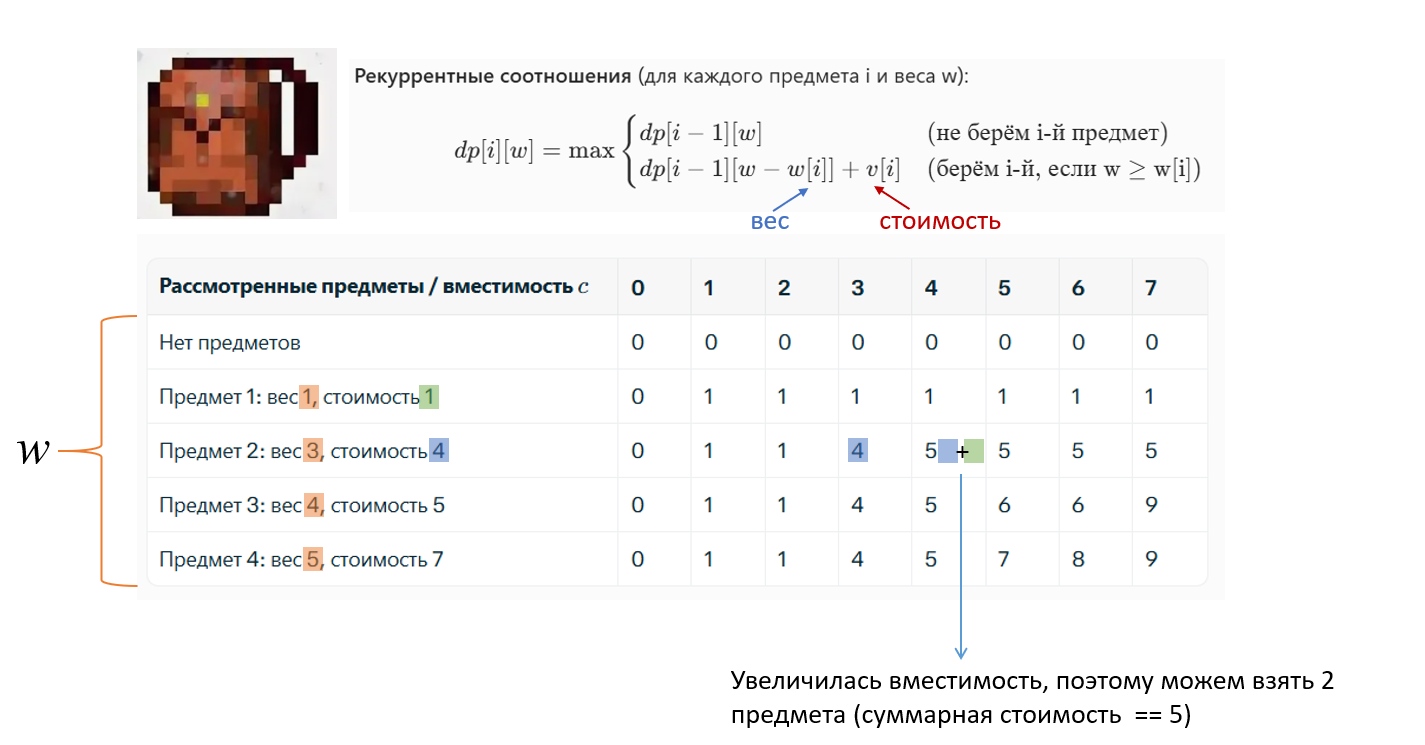

In [3]:
def knapsack(weights, values, capacity):
    """
    - capacity — целое неотрицательное число;
    - weights — положительные целые веса;
    - values — неотрицательные стоимости.

    Возвращает:
    - максимальную стоимость;
    - номера выбранных предметов, начиная с 1.
    """

    n = len(weights)

    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        weight = weights[i - 1]
        value = values[i - 1]

        for c in range(capacity + 1):
            # Вариант 1: не брать текущий предмет.
            dp[i][c] = dp[i - 1][c]

            # Вариант 2: взять, если хватает вместимости.
            if weight <= c:
                candidate = value + dp[i - 1][c - weight]
                dp[i][c] = max(dp[i][c], candidate)

    # Восстановление одного из оптимальных наборов.
    selected = []
    c = capacity

    for i in range(n, 0, -1):
        if dp[i][c] != dp[i - 1][c]:
            selected.append(i)
            c -= weights[i - 1]

    selected.reverse()

    return dp[n][capacity], selected


weights = [1, 3, 4, 5]
values = [1, 4, 5, 7]
capacity = 7

best_value, selected = knapsack(weights, values, capacity)

total_weight = sum(weights[i - 1] for i in selected)

print("Максимальная стоимость:", best_value)
print("Номера предметов:", selected)
print("Общий вес:", total_weight)

Максимальная стоимость: 9
Номера предметов: [2, 3]
Общий вес: 7


**Сложность**  
**Время**: $O(n·W)$ — два вложенных цикла.

**Память**: $O(n·W)$ для таблицы.

**Восстановление решения**  
Чтобы узнать, какие предметы взять: после заполнения таблицы идем от $p[n][W]$ назад:

* Если $dp[i][w]=dp[i−1][w]$, пропускаем $i$-й предмет.

* Иначе берём $i$-й предмет, переходим к $dp[i−1][w−w[i]]$.​

# 11. Динамическое программирование на матрицах. Подсчет чисел Фибоначчи за $O(log n)$.

Число Фибоначчи $F_n$ можно вычислить за $O(logn)$ арифметических операций, если представить переход между соседними состояниями в виде умножения на матрицу и применить быстрое возведение в степень. Вместо последовательного вычисления всех $F_0,…,F_n$ мы объединяем сразу большие блоки переходов.

Важно различать два понятия: динамическое программирование в двумерной таблице, как в задаче о рюкзаке, и ускорение динамического программирования с помощью матрицы перехода. Для быстрого вычисления Фибоначчи используется второй подход.



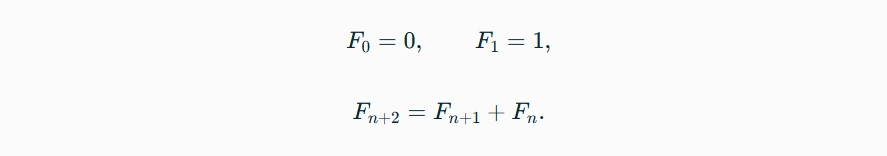

Обычное динамическое программирование вычисляет числа последовательно:

```python
def fibonacci_linear(n):
    a, b = 0, 1

    for _ in range(n):
        a, b = b, a + b

    return a
```
Здесь пара $(a, b)$ хранит два соседних числа Фибоначчи. Выполняется $n$ переходов, поэтому требуется $O(n)$ арифметических операций.

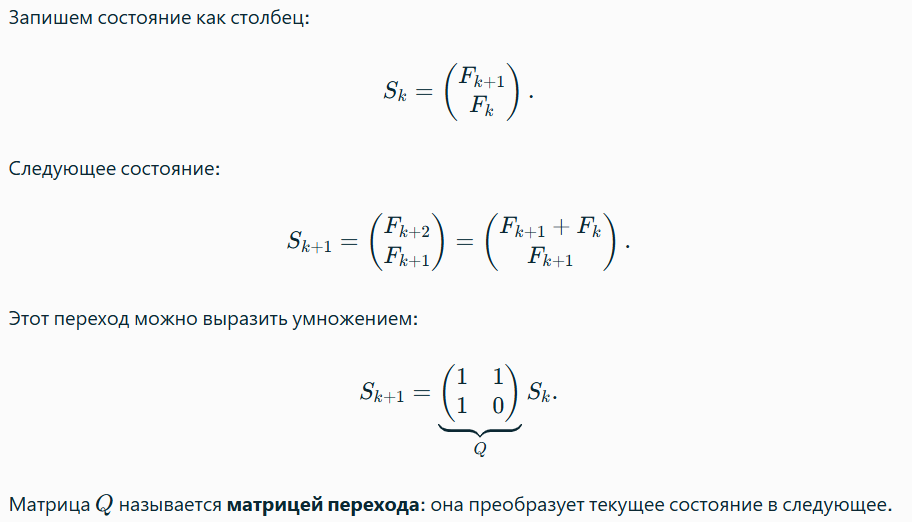

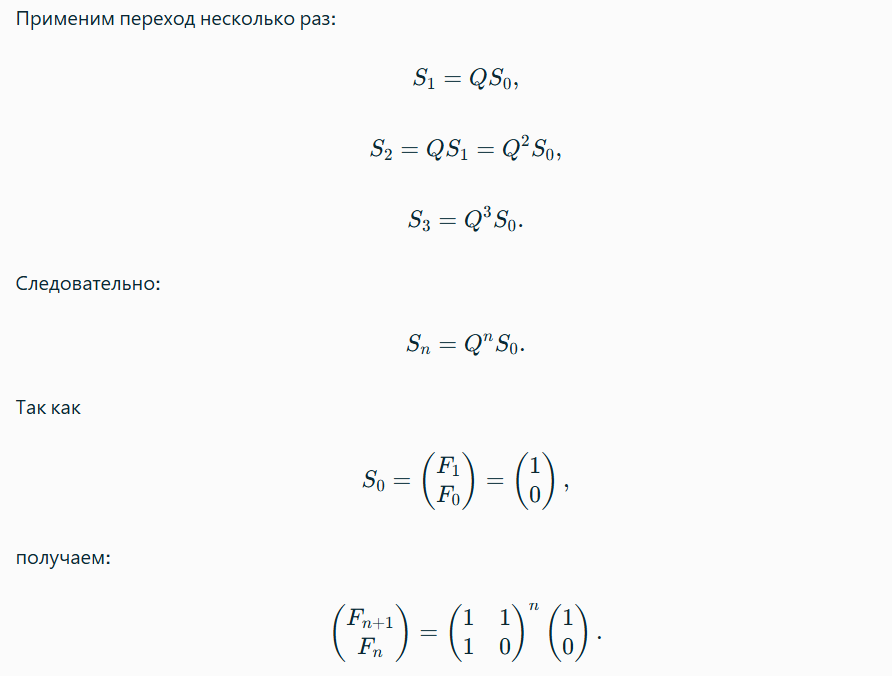

Поэтому $F_n$ — элемент с индексами $[1][0]$ матрицы
$Q^n$. Эта формулировка работает и для $n=0$, поскольку $Q^0 = I$, где $I$ — единичная матрица.



Если перемножать $Q$ само на себя $n$ раз, ускорения не получится. Нужен алгоритм бинарного возведения в степень.

***Примечание автора***: алгоритм мы уже встречали, смотрите пример №3 в билете про рекурсию (№1)

Он использует равенства:

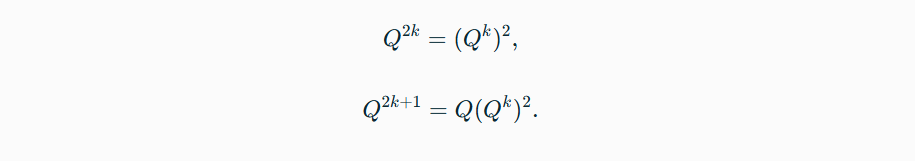

На каждом шаге показатель уменьшается примерно вдвое, поэтому число шагов логарифмическое. Для матриц этот метод применим благодаря ассоциативности умножения; коммутативность не требуется.
Например:

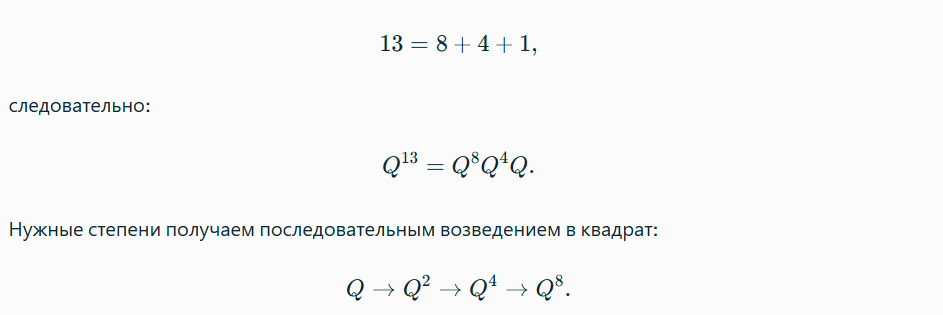

Мы не выполняем все 13 последовательных переходов, а составляем результат из переходов длиной 1, 4 и 8. Для матриц $2×2$ удобно явно записать формулы умножения. NumPy здесь не нужен (но можно).

In [4]:
def multiply_2x2(a, b):
    """Умножение двух матриц 2 x 2."""
    return (
        (
            a[0][0] * b[0][0] + a[0][1] * b[1][0],
            a[0][0] * b[0][1] + a[0][1] * b[1][1],
        ),
        (
            a[1][0] * b[0][0] + a[1][1] * b[1][0],
            a[1][0] * b[0][1] + a[1][1] * b[1][1],
        ),
    )


def matrix_power(matrix, exponent):
    """Возведение матрицы 2 x 2 в целую неотрицательную степень."""
    if not isinstance(exponent, int):
        raise TypeError("Показатель степени должен быть целым")
    if exponent < 0:
        raise ValueError("Показатель степени должен быть неотрицательным")

    result = (
        (1, 0),
        (0, 1),
    )

    base = matrix

    while exponent > 0:
        if exponent % 2 == 1:
            result = multiply_2x2(result, base)

        base = multiply_2x2(base, base)
        exponent //= 2

    return result


def fibonacci(n):
    """Возвращает F(n), где F(0) = 0, F(1) = 1."""
    q = (
        (1, 1),
        (1, 0),
    )

    return matrix_power(q, n)[1][0]


for n in range(11):
    print(f"F({n}) = {fibonacci(n)}")

print("F(50) =", fibonacci(50))

F(0) = 0
F(1) = 1
F(2) = 1
F(3) = 2
F(4) = 3
F(5) = 5
F(6) = 8
F(7) = 13
F(8) = 21
F(9) = 34
F(10) = 55
F(50) = 12586269025


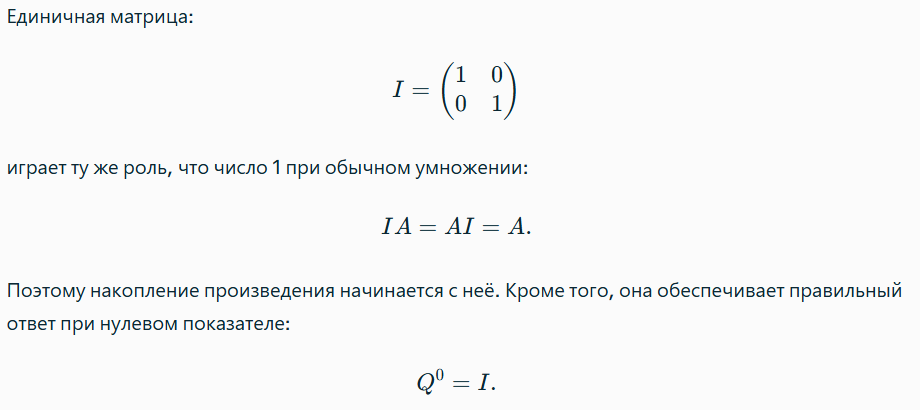

### Как это связано с другими задачами динамического программирования



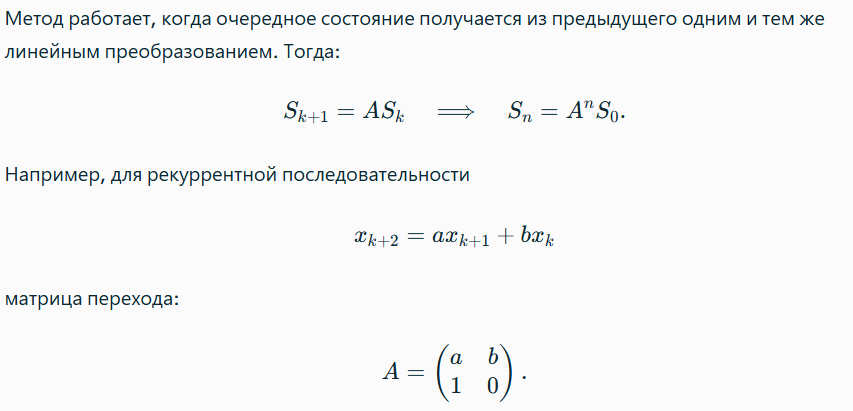

Фибоначчи — частный случай $a=b=1$.

Пока всё. Всем удачи! ✌